In [9]:
#Importe de librerias necesarias 
import numpy as np
import pandas as pd
from geopy.geocoders import Nominatim   # OpenStreetMap, 1 consulta/seg
import time
import matplotlib.pyplot as plt
import requests
import time
from typing import Union, List, Optional, Tuple

In [10]:
def distancias_cap_provincias(
    ciudades: List[str]
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Calcula la matriz de distancias geodésicas (en línea recta) entre una lista
    de capitales provinciales usando la fórmula del semiverseno (Haversine).

    Parámetros (Entradas):
    -----------------------
    ciudades : List[str]
        Lista con los nombres de las ciudades/capitales a geolocalizar.

    Retorna (Salidas):
    ------------------
    Tuple[np.ndarray, np.ndarray]
        - D_recta (np.ndarray): Matriz simétrica (N x N) con las distancias
          en kilómetros entre cada par de ciudades.
        - coords_grados (np.ndarray): Matriz (N x 2) con las coordenadas
          en grados decimales [latitud, longitud] de cada ciudad.
    """
    # Inicialización del geocodificador con timeout preventivo de 10 segundos
    geo = Nominatim(user_agent="tp-tsp-espana", timeout=10)
    coords_lista = []

    for c in ciudades:
        loc = geo.geocode(f"{c}, España")
        if loc is None:
            raise ValueError(f"No se pudieron encontrar las coordenadas para: {c}")
        
        coords_lista.append((loc.latitude, loc.longitude))
        time.sleep(1.1)  # Respetar la política de uso de OSM (máx. 1 req/seg)
    
    # Coordenadas en grados (N x 2)
    coords_grados = np.array(coords_lista)

    # Conversión a radianes para cálculo trigonométrico
    coords_rads = np.radians(coords_grados)
    lat, lon = coords_rads[:, 0][:, None], coords_rads[:, 1][:, None]

    # Fórmula del semiverseno (Haversine)
    a = (np.sin((lat - lat.T) / 2) ** 2 + 
         np.cos(lat) * np.cos(lat.T) * np.sin((lon - lon.T) / 2) ** 2)
    
    # Matriz final de distancias en kilómetros (Radio de la Tierra: 6371.0 km)
    D_recta = 2 * 6371.0 * np.arcsin(np.sqrt(a))

    return D_recta, coords_grados


In [11]:
#Ejecucion de la funcion 
ciudades_espana = [
    "A Coruña", "Albacete", "Alicante", "Almería", "Ávila", "Badajoz",
    "Barcelona", "Bilbao", "Burgos", "Cáceres", "Cádiz", "Castellón de la Plana",
    "Ciudad Real", "Córdoba", "Cuenca", "Girona", "Granada", "Guadalajara",
    "Huelva", "Huesca", "Jaén", "León", "Lleida", "Logroño", "Lugo", "Madrid",
    "Málaga", "Murcia", "Ourense", "Oviedo", "Palencia", "Pamplona",
    "Pontevedra", "Salamanca", "San Sebastián", "Santander", "Segovia",
    "Sevilla", "Soria", "Tarragona", "Teruel", "Toledo", "Valencia",
    "Valladolid", "Vitoria-Gasteiz", "Zamora", "Zaragoza"
]

Matriz_distancias_rectas, lat_long_provincias = distancias_cap_provincias(ciudades_espana)


In [12]:
print(Matriz_distancias_rectas)

[[  0.         731.22753738 867.51826029 ... 470.18882255 274.00721896
  641.62795305]
 [731.22753738   0.         139.09232476 ... 434.01398115 457.57415456
  310.35942523]
 [867.51826029 139.09232476   0.         ... 533.63180812 594.63956657
  374.0034816 ]
 ...
 [470.18882255 434.01398115 533.63180812 ...   0.         299.39826719
  193.31457597]
 [274.00721896 457.57415456 594.63956657 ... 299.39826719   0.
  417.79885401]
 [641.62795305 310.35942523 374.0034816  ... 193.31457597 417.79885401
    0.        ]]


In [13]:
def graficar_y_exportar_ciudades(
    coordenadas: Union[np.ndarray, List],
    nombres_ciudades: Optional[List[str]] = None,
    nombre_archivo: str = "mapa_ciudades_tsp.png",
    dpi: int = 300
) -> str:
    """
    Grafica la ubicación geográfica de las ciudades (puntos del TSP) y
    exporta el gráfico como una imagen en disco.

    Parámetros (Entradas):
    -----------------------
    coordenadas : Union[np.ndarray, List]
        Matriz o lista de tamaño (N, 2) con las coordenadas [latitud, longitud].
    nombres_ciudades : Optional[List[str]], opcional
        Lista con los nombres de las ciudades para etiquetarlas. Si no se
        proporciona, se etiquetan con su índice numérico (0, 1, 2, ...).
    nombre_archivo : str, opcional
        Nombre o ruta del archivo de imagen a generar (por defecto "mapa_ciudades_tsp.png").
    dpi : int, opcional
        Resolución de la imagen exportada en puntos por pulgada (por defecto 300 DPI).

    Retorna (Salida):
    ------------------
    str
        Ruta o nombre del archivo de imagen exportado exitosamente.
    """
    coords_arr = np.array(coordenadas)

    # Asegurar que las coordenadas estén en grados decimales
    if np.max(coords_arr) < 7:  # Si los valores son pequeños, están en radianes
        coords_deg = np.degrees(coords_arr)
    else:
        coords_deg = coords_arr

    lats = coords_deg[:, 0]
    lons = coords_deg[:, 1]

    # Crear figura
    fig, ax = plt.subplots(figsize=(10, 7))

    # Graficar puntos: Longitud en X (horizontal), Latitud en Y (vertical)
    ax.scatter(lons, lats, c='crimson', s=60, edgecolors='black', zorder=2)

    # Etiquetar cada punto (con nombre si existe, o con índice numérico)
    for i, (lat, lon) in enumerate(zip(lats, lons)):
        etiqueta = nombres_ciudades[i] if nombres_ciudades is not None else str(i)
        ax.annotate(etiqueta, (lon, lat), textcoords="offset points", 
                    xytext=(5, 5), fontsize=8, alpha=0.85)

    ax.set_title("Ubicación de las Ciudades (Puntos del TSP)", fontsize=13, pad=12)
    ax.set_xlabel("Longitud (°)", fontsize=11)
    ax.set_ylabel("Latitud (°)", fontsize=11)
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.axis('equal')  # Mantener proporciones geográficas reales

    # Exportar imagen a disco
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=dpi, bbox_inches='tight')
    plt.show()

    print(f"Imagen exportada con éxito en: {nombre_archivo}")
    return nombre_archivo


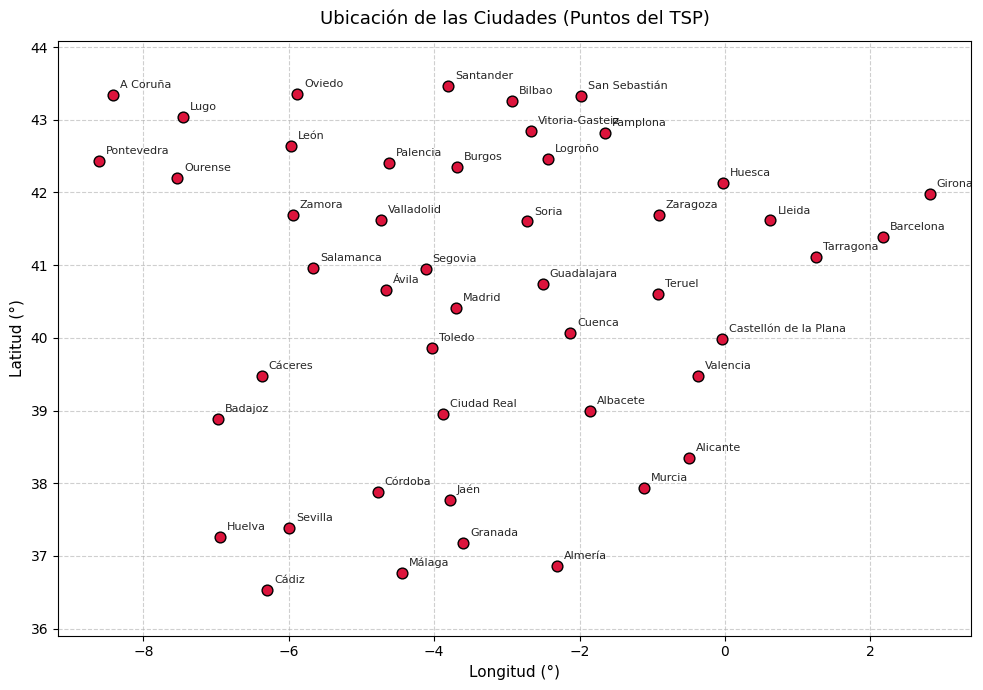

Imagen exportada con éxito en: mapa_espana_provincias.png


In [14]:
ruta_imagen = graficar_y_exportar_ciudades(
    coordenadas=lat_long_provincias,
    nombres_ciudades=ciudades_espana,
    nombre_archivo="mapa_espana_provincias.png"
)


In [15]:
def calcular_distancias_y_tiempos_osrm(
    coordenadas: Union[np.ndarray, List],
    nombres_ciudades: Optional[List[str]] = None,
    archivo_distancias_csv: Optional[str] = "matriz_distancias_carretera.csv",
    archivo_tiempos_csv: Optional[str] = "matriz_tiempos_carretera.csv",
    timeout: int = 30
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Calcula simultáneamente la matriz de distancias (en km) y la matriz de tiempos
    (en horas) por carretera usando la API de OSRM, y exporta ambas a formato CSV.

    Parámetros (Entradas):
    -----------------------
    coordenadas : Union[np.ndarray, List]
        Matriz o lista (N, 2) con las coordenadas [latitud, longitud].
    nombres_ciudades : Optional[List[str]], opcional
        Nombres de las ciudades para encabezados de filas y columnas en los CSV.
    archivo_distancias_csv : Optional[str], opcional
        Nombre del archivo CSV para la matriz de distancias (en km). Si es None, no se guarda.
    archivo_tiempos_csv : Optional[str], opcional
        Nombre del archivo CSV para la matriz de tiempos (en horas). Si es None, no se guarda.
    timeout : int, opcional
        Tiempo máximo de espera para la consulta HTTP (por defecto 30 segundos).

    Retorna (Salidas):
    ------------------
    Tuple[np.ndarray, np.ndarray]
        - D_carretera (np.ndarray): Matriz (N x N) de distancias por carretera en kilómetros.
        - T_carretera (np.ndarray): Matriz (N x N) de tiempos de conducción en horas.
    """
    coords_arr = np.array(coordenadas)

    # 1. Asegurar coordenadas en grados decimales
    if np.max(coords_arr) < 7:
        coords_grados = np.degrees(coords_arr)
    else:
        coords_grados = coords_arr

    # 2. Formatear para OSRM ("longitud,latitud")
    coords_str = ";".join([f"{lon:.6f},{lat:.6f}" for lat, lon in coords_grados])
    
    # 3. Pedir ambas métricas: duration (tiempo) y distance (distancia)
    url = f"http://router.project-osrm.org/table/v1/driving/{coords_str}?annotations=duration,distance"

    try:
        response = requests.get(url, timeout=timeout)
        response.raise_for_status()
        data = response.json()
    except requests.exceptions.RequestException as e:
        raise RuntimeError(f"Error de conexión con OSRM: {e}")

    if data.get("code") != "Ok":
        raise RuntimeError(f"Error devuelto por OSRM: {data.get('message', data)}")

    # 4. Conversión de unidades
    # Distancias: de metros a kilómetros
    D_carretera = np.array(data["distances"]) / 1000.0
    
    # Tiempos: de segundos a horas decimales
    T_carretera = np.array(data["durations"]) / 3600.0

    encabezados = nombres_ciudades if nombres_ciudades is not None else range(len(D_carretera))

    # 5. Guardar matriz de distancias en CSV
    if archivo_distancias_csv:
        df_dist = pd.DataFrame(D_carretera.round(2), index=encabezados, columns=encabezados)
        df_dist.to_csv(archivo_distancias_csv, encoding="utf-8-sig")
        print(f"Matriz de distancias guardada en: {archivo_distancias_csv}")

    # 6. Guardar matriz de tiempos en CSV
    if archivo_tiempos_csv:
        df_tiempo = pd.DataFrame(T_carretera.round(2), index=encabezados, columns=encabezados)
        df_tiempo.to_csv(archivo_tiempos_csv, encoding="utf-8-sig")
        print(f"Matriz de tiempos guardada en: {archivo_tiempos_csv}")

    # Estadísticas resumidas
    print("\n--- Resumen de Resultados ---")
    print("Dimensiones de las matrices:", D_carretera.shape)
    print("Distancia máxima por carretera:", round(D_carretera.max(), 2), "km")
    print("Tiempo máximo de conducción:", round(T_carretera.max(), 2), "horas")

    return D_carretera, T_carretera


In [16]:
Matriz_distancias_km, Matriz_tiempos_horas = calcular_distancias_y_tiempos_osrm(
    coordenadas=lat_long_provincias,
    nombres_ciudades=ciudades_espana,
    archivo_distancias_csv="matriz_distancias_carretera.csv",
    archivo_tiempos_csv="matriz_tiempos_carretera.csv"
)

Matriz de distancias guardada en: matriz_distancias_carretera.csv
Matriz de tiempos guardada en: matriz_tiempos_carretera.csv

--- Resumen de Resultados ---
Dimensiones de las matrices: (47, 47)
Distancia máxima por carretera: 1212.48 km
Tiempo máximo de conducción: 13.31 horas


In [22]:
print(Matriz_tiempos_horas)

[[ 0.          9.25469444 10.95555556 ...  6.49994444  4.62205556
   8.66219444]
 [ 9.23366667  0.          1.89588889 ...  6.60555556  6.51416667
   4.96733333]
 [10.91858333  1.88861111  0.         ...  8.17438889  8.19908333
   5.65802778]
 ...
 [ 6.46911111  6.61655556  8.13602778 ...  0.          4.49377778
   3.09202778]
 [ 4.61322222  6.52283333  8.22369444 ...  4.50891667  0.
   6.67116667]
 [ 8.59858333  4.96216667  5.61858333 ...  3.06855556  6.62325
   0.        ]]


In [33]:
def graficar_y_exportar_red_carreteras(
    coordenadas: Union[np.ndarray, List],
    matriz_distancias: np.ndarray,
    nombres_ciudades: List[str],
    k_vecinos: int = 7,
    nombre_archivo: str = "red_vial_espana_tsp.png",
    dpi: int = 300
) -> str:
    """
    Grafica la red vial de las ciudades conectando cada una con sus vecinos
    más cercanos por carretera, colorea los nodos según su accesibilidad media
    y exporta el gráfico como imagen en disco.

    Parámetros (Entradas):
    -----------------------
    coordenadas : Union[np.ndarray, List]
        Matriz o lista de tamaño (N, 2) con las coordenadas [latitud, longitud].
    matriz_distancias : np.ndarray
        Matriz simétrica (N x N) con las distancias de conducción por carretera (en km).
    nombres_ciudades : List[str]
        Lista con los nombres de las ciudades correspondientes a cada índice.
    k_vecinos : int, opcional
        Cantidad de ciudades vecinas más cercanas a conectar con cada punto (por defecto 4).
    nombre_archivo : str, opcional
        Nombre o ruta del archivo de imagen a generar (por defecto "red_vial_espana_tsp.png").
    dpi : int, opcional
        Resolución de la imagen exportada en puntos por pulgada (por defecto 300 DPI).

    Retorna (Salida):
    ------------------
    str
        Ruta o nombre del archivo de imagen exportado exitosamente.
    """
    coords_arr = np.array(coordenadas)

    # 1. Asegurar coordenadas en grados decimales
    if np.max(coords_arr) < 7:
        coords_deg = np.degrees(coords_arr)
    else:
        coords_deg = coords_arr

    lats = coords_deg[:, 0]
    lons = coords_deg[:, 1]

    # Distancia promedio de cada ciudad al resto (para el mapa de calor)
    dist_promedio = np.mean(matriz_distancias, axis=1)

    # 2. Configurar la figura
    fig, ax = plt.subplots(figsize=(14, 10))

    # 3. Trazar conexiones a los k vecinos más cercanos por carretera
    lineas_dibujadas = set()
    for i in range(len(coords_deg)):
        # Índices ordenados por menor distancia (se excluye el índice 0 que es la misma ciudad)
        vecinos = np.argsort(matriz_distancias[i])[1 : k_vecinos + 1]
        for j in vecinos:
            par = tuple(sorted((i, j)))
            if par not in lineas_dibujadas:
                lineas_dibujadas.add(par)
                # Línea discontinua
                ax.plot([lons[i], lons[j]], [lats[i], lats[j]], 
                        color='gray', linestyle='--', linewidth=1.0, alpha=0.6, zorder=1)
                
                # Texto con la distancia en kilómetros en el punto medio
                mid_lon = (lons[i] + lons[j]) / 2
                mid_lat = (lats[i] + lats[j]) / 2
                dist_km = int(matriz_distancias[i, j])
                ax.text(mid_lon, mid_lat, f"{dist_km} km", 
                        fontsize=7, color='darkblue', alpha=0.8, ha='center',
                        bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.6))

    # 4. Graficar nodos/ciudades
    scatter = ax.scatter(lons, lats, c=dist_promedio, cmap='plasma', s=120, 
                         edgecolors='black', linewidth=1.2, zorder=3)

    # 5. Etiquetar cada ciudad con su índice y nombre
    for i, (nombre, lat, lon) in enumerate(zip(nombres_ciudades, lats, lons)):
        ax.annotate(f"{i}. {nombre}", (lon, lat), 
                    textcoords="offset points", xytext=(4, 4), 
                    fontsize=8, fontweight='semibold', color='black', zorder=4)

    # 6. Barra de color y títulos
    cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.03, pad=0.02)
    cbar.set_label('Distancia media al resto de ciudades por carretera (km)', fontsize=10)

    ax.set_title("Red Vial de España - Puntos del TSP con Distancias Reales por Carretera (OSRM)", fontsize=13, pad=15)
    ax.set_xlabel("Longitud (°)", fontsize=11)
    ax.set_ylabel("Latitud (°)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.axis('equal')  # Mantener proporciones geográficas reales

    # 7. Guardar y mostrar
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=dpi, bbox_inches='tight')
    plt.show()

    print(f"Imagen exportada con éxito en: {nombre_archivo}")
    return nombre_archivo


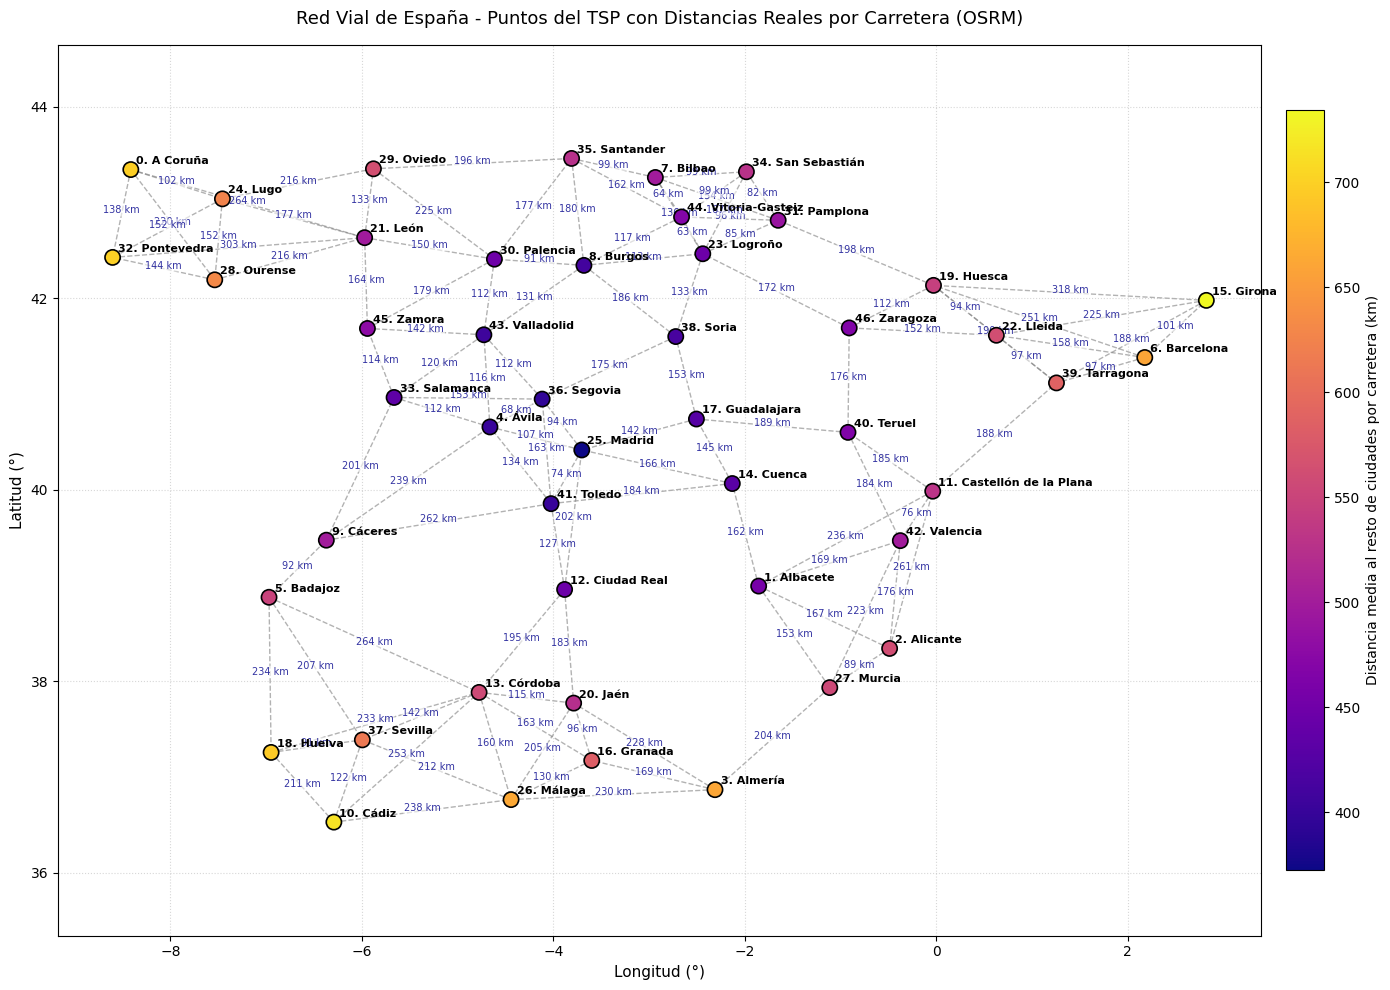

Imagen exportada con éxito en: red_vial_espana_tsp.png


In [21]:
ruta_red_vial = graficar_y_exportar_red_carreteras(
    coordenadas=lat_long_provincias,
    matriz_distancias=Matriz_distancias_km,
    nombres_ciudades=ciudades_espana,
    k_vecinos=4,
    nombre_archivo="red_vial_espana_tsp.png"
)


In [30]:
def graficar_y_exportar_red_tiempos(
    coordenadas: Union[np.ndarray, List],
    matriz_tiempos: np.ndarray,
    nombres_ciudades: List[str],
    k_vecinos: int = 4,
    nombre_archivo: str = "red_tiempos_espana_tsp.png",
    dpi: int = 300
) -> str:
    """
    Grafica la red de conectividad temporal de las ciudades conectando cada una
    con sus vecinos más cercanos en tiempo de conducción, colorea los nodos
    según su tiempo medio de viaje y exporta el gráfico como imagen en disco.

    Parámetros (Entradas):
    -----------------------
    coordenadas : Union[np.ndarray, List]
        Matriz o lista de tamaño (N, 2) con las coordenadas [latitud, longitud].
    matriz_tiempos : np.ndarray
        Matriz simétrica (N x N) con los tiempos de viaje por carretera (en horas).
    nombres_ciudades : List[str]
        Lista con los nombres de las ciudades correspondientes a cada índice.
    k_vecinos : int, opcional
        Cantidad de ciudades más cercanas en tiempo a conectar con cada nodo (por defecto 4).
    nombre_archivo : str, opcional
        Nombre o ruta del archivo de imagen a generar (por defecto "red_tiempos_espana_tsp.png").
    dpi : int, opcional
        Resolución de la imagen exportada en puntos por pulgada (por defecto 300 DPI).

    Retorna (Salida):
    ------------------
    str
        Ruta o nombre del archivo de imagen exportado exitosamente.
    """
    coords_arr = np.array(coordenadas)

    # 1. Asegurar coordenadas en grados decimales
    if np.max(coords_arr) < 7:
        coords_deg = np.degrees(coords_arr)
    else:
        coords_deg = coords_arr

    lats = coords_deg[:, 0]
    lons = coords_deg[:, 1]

    # Tiempo promedio de conducción de cada ciudad hacia el resto (en horas)
    tiempo_promedio = np.mean(matriz_tiempos, axis=1)

    # 2. Configurar la figura
    fig, ax = plt.subplots(figsize=(14, 10))

    # 3. Trazar conexiones a los k vecinos más rápidos en tiempo
    lineas_dibujadas = set()
    for i in range(len(coords_deg)):
        # Índices ordenados por menor tiempo de viaje (excluyendo la misma ciudad [índice 0])
        vecinos = np.argsort(matriz_tiempos[i])[1 : k_vecinos + 1]
        for j in vecinos:
            par = tuple(sorted((i, j)))
            if par not in lineas_dibujadas:
                lineas_dibujadas.add(par)
                # Línea discontinua
                ax.plot([lons[i], lons[j]], [lats[i], lats[j]], 
                        color='teal', linestyle='--', linewidth=1.0, alpha=0.6, zorder=1)
                
                # Texto con el tiempo en horas en el punto medio
                mid_lon = (lons[i] + lons[j]) / 2
                mid_lat = (lats[i] + lats[j]) / 2
                tiempo_h = matriz_tiempos[i, j]
                
                # Formato legible: ej. "1.2 h" o "45 min" si es menor a 1 hora
                texto_tiempo = f"{tiempo_h:.1f} h" if tiempo_h >= 1.0 else f"{int(tiempo_h * 60)} min"
                
                ax.text(mid_lon, mid_lat, texto_tiempo, 
                        fontsize=7, color='darkgreen', alpha=0.85, ha='center',
                        bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.7))

    # 4. Graficar nodos/ciudades (coloreados por tiempo promedio con mapa 'viridis')
    scatter = ax.scatter(lons, lats, c=tiempo_promedio, cmap='viridis', s=120, 
                         edgecolors='black', linewidth=1.2, zorder=3)

    # 5. Etiquetar cada ciudad con su índice y nombre
    for i, (nombre, lat, lon) in enumerate(zip(nombres_ciudades, lats, lons)):
        ax.annotate(f"{i}. {nombre}", (lon, lat), 
                    textcoords="offset points", xytext=(4, 4), 
                    fontsize=8, fontweight='semibold', color='black', zorder=4)

    # 6. Barra de color y títulos
    cbar = fig.colorbar(scatter, ax=ax, orientation='vertical', fraction=0.03, pad=0.02)
    cbar.set_label('Tiempo medio de viaje al resto de ciudades (horas)', fontsize=10)

    ax.set_title("Red Temporal de España - Tiempos Reales de Conducción (OSRM)", fontsize=13, pad=15)
    ax.set_xlabel("Longitud (°)", fontsize=11)
    ax.set_ylabel("Latitud (°)", fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.axis('equal')  # Mantener proporciones geográficas reales

    # 7. Guardar y mostrar
    plt.tight_layout()
    plt.savefig(nombre_archivo, dpi=dpi, bbox_inches='tight')
    plt.show()

    print(f"Imagen exportada con éxito en: {nombre_archivo}")
    return nombre_archivo


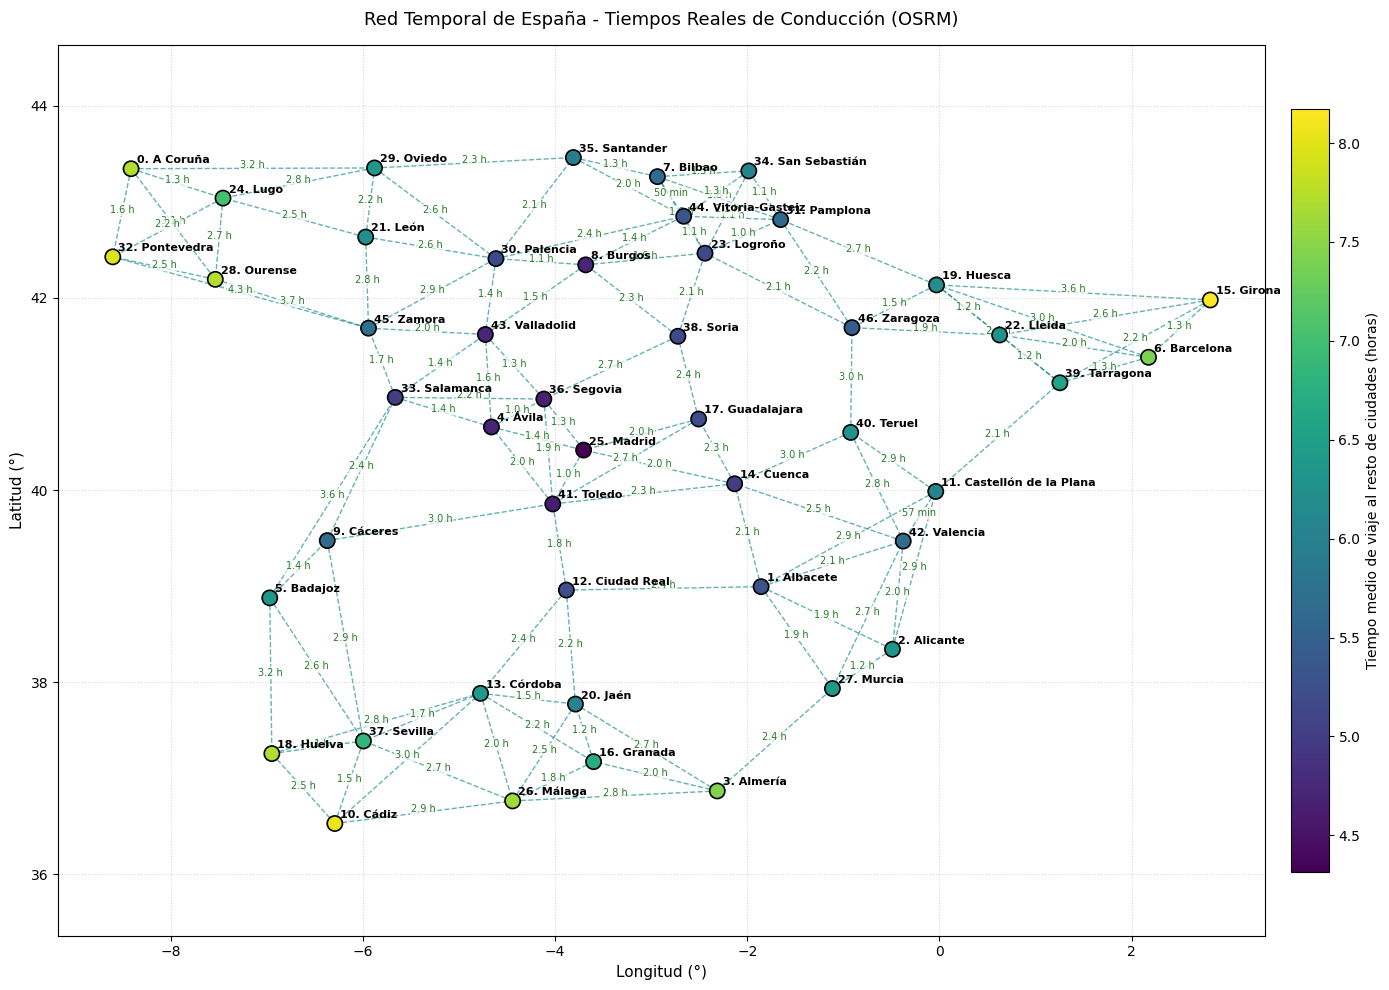

Imagen exportada con éxito en: red_tiempos_espana_tsp.png


In [24]:
ruta_imagen_tiempos = graficar_y_exportar_red_tiempos(
    coordenadas=lat_long_provincias,
    matriz_tiempos=Matriz_tiempos_horas,
    nombres_ciudades=ciudades_espana,
    k_vecinos=4,
    nombre_archivo="red_tiempos_espana_tsp.png"
)
